<a href="https://colab.research.google.com/github/tahta-id/Project-Google-Colab/blob/main/pcb_defect_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
pip install kagglehub opencv-python numpy pandas tensorflow scikit-learn seaborn matplotlib

--- Mengunduh Dataset PCB Defect via kagglehub ---


100%|██████████| 1.10G/1.10G [00:12<00:00, 94.1MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/norbertelter/pcb-defect-dataset/versions/2
Total gambar valid yang siap diproses: 10668
Daftar Kelas PCB Defect: ['images']
Sampel citra PCB untuk Modul 1-3: /root/.cache/kagglehub/datasets/norbertelter/pcb-defect-dataset/versions/2/pcb-defect-dataset/train/images/rotation_270_light_04_mouse_bite_12_1_600.jpg



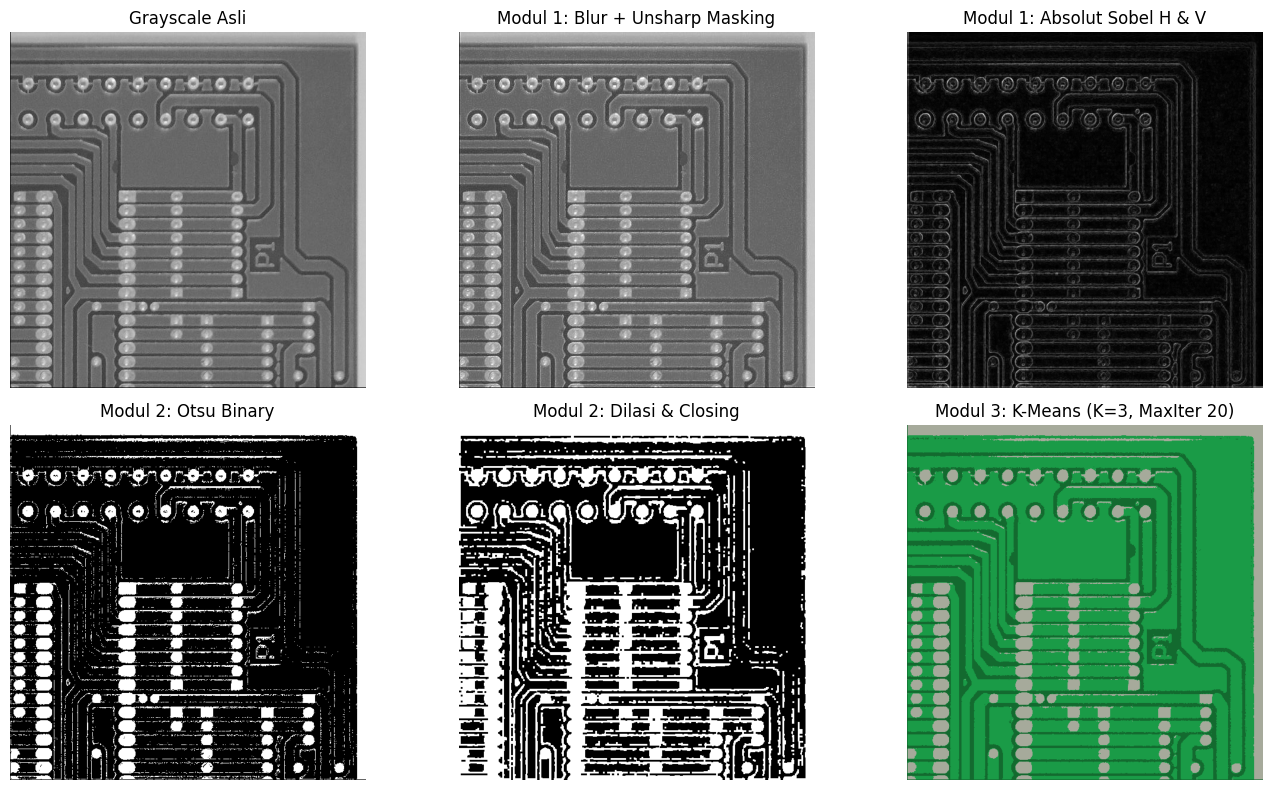


--- Modul 4: Membagi Dataset & Menyiapkan Data Generator ---
Found 8534 validated image filenames belonging to 1 classes.
Found 2134 validated image filenames belonging to 1 classes.
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

--- Melatih Model EfficientNetB0 PCB Defect Detector ---
Epoch 1/3


/usr/local/lib/python3.13/dist-packages/keras/src/ops/nn.py:947: UserWarning: You are using a softmax over axis -1 of a tensor of shape (None, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/keras/src/losses/losses.py:33: SyntaxWarning: In loss categorical_crossentropy, expected y_pred.shape to be (batch_size, num_classes) with num_classes > 1. Received: y_pred.shape=(None, 1). Consider using 'binary_crossentropy' if you only have 2 classes.
  return self.fn(y_true, y_pred, **self._fn_kwargs)


267/267 ━━━━━━━━━━━━━━━━━━━━ 321s 1s/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 2/3
267/267 ━━━━━━━━━━━━━━━━━━━━ 320s 1s/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 3/3
267/267 ━━━━━━━━━━━━━━━━━━━━ 342s 1s/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00

--- Evaluasi Prediksi pada Data Validasi ---


/usr/local/lib/python3.13/dist-packages/keras/src/ops/nn.py:947: UserWarning: You are using a softmax over axis -1 of a tensor of shape (32, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnings.warn(


67/67 ━━━━━━━━━━━━━━━━━━━━ 66s 931ms/step

================ CLASSIFICATION REPORT ================
              precision    recall  f1-score   support

      images       1.00      1.00      1.00      2134

    accuracy                           1.00      2134
   macro avg       1.00      1.00      1.00      2134
weighted avg       1.00      1.00      1.00      2134



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


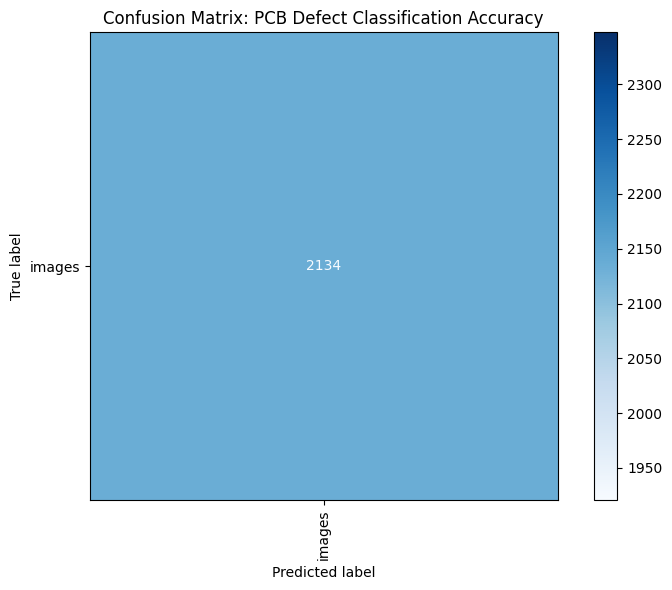

In [2]:
import os
import glob
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import kagglehub

# =====================================================================
# 0. UNDUH DATASET PCB DEFECT MENGGUNAKAN KAGGLEHUB & PERSIAPAN DATA
# =====================================================================
print("--- Mengunduh Dataset PCB Defect via kagglehub ---")
path = kagglehub.dataset_download("norbertelter/pcb-defect-dataset")
print("Path to dataset files:", path)

# 1. Cari semua file gambar (.png / .jpg / .jpeg) di seluruh subfolder dataset
image_files = glob.glob(os.path.join(path, "**", "*.png"), recursive=True) + \
              glob.glob(os.path.join(path, "**", "*.jpg"), recursive=True) + \
              glob.glob(os.path.join(path, "**", "*.jpeg"), recursive=True)

if not image_files:
    raise FileNotFoundError("Tidak ditemukan file gambar di dalam dataset PCB!")

# 2. Buat DataFrame berdasarkan folder kategori/kelas defect
data = []
for img_path in image_files:
    # Mengambil nama folder tempat gambar berada sebagai nama kelas
    class_name = os.path.basename(os.path.dirname(img_path))
    data.append({'file_path': img_path, 'class_str': class_name})

df = pd.DataFrame(data)

# Filter folder utama/non-kelas jika ada (misal folder 'images' umum)
class_counts = df['class_str'].value_counts()
valid_classes = class_counts[class_counts > 5].index
df = df[df['class_str'].isin(valid_classes)].reset_index(drop=True)

print(f"Total gambar valid yang siap diproses: {len(df)}")
print(f"Daftar Kelas PCB Defect: {df['class_str'].unique().tolist()}")

# Ambil 1 sampel gambar PCB untuk demonstrasi Modul 1-3
sample_img_path = df['file_path'].iloc[0]
print(f"Sampel citra PCB untuk Modul 1-3: {sample_img_path}\n")


# =====================================================================
# MODUL 1: Blur Reduksi Kerlip, Unsharp Masking & Magnitudo Absolut Sobel
# =====================================================================
def modul_1_processing(image_path):
    img_bgr = cv2.imread(image_path)
    if img_bgr is None:
        raise ValueError(f"Gagal memuat citra: {image_path}")

    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

    # 1. Reduksi kerlip cahaya metalik papan dengan matriks pemburaman Gaussian (5x5)
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)

    # 2. Pertegas struktur retakan halus atau scratch lewat unsharp masking
    detail = cv2.subtract(gray, blurred)
    sharpened = cv2.addWeighted(gray, 1.0, detail, 1.5, 0)

    # 3. Ekstrak koordinat garis tembaga dengan normalisasi magnitudo absolut Sobel vertikal dan horizontal
    sobel_x = cv2.Sobel(sharpened, cv2.CV_64F, 1, 0, ksize=3)
    sobel_y = cv2.Sobel(sharpened, cv2.CV_64F, 0, 1, ksize=3)

    # Magnitudo Absolut
    abs_sobel_x = np.absolute(sobel_x)
    abs_sobel_y = np.absolute(sobel_y)
    sobel_mag = cv2.addWeighted(abs_sobel_x, 0.5, abs_sobel_y, 0.5, 0)

    sobel_uint8 = cv2.normalize(sobel_mag, None, 0, 255, cv2.NORM_MINMAX, dtype=cv2.CV_8U)

    return gray, sharpened, sobel_uint8


# =====================================================================
# MODUL 2: Otsu Thresholding, Dilasi & Closing Morfologi
# =====================================================================
def modul_2_processing(sharpened_img):
    # 1. Pisahkan tembaga (foreground) dari fiberglass (background) via Otsu thresholding otomatis
    _, otsu_thresh = cv2.threshold(sharpened_img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    # 2. Lakukan dilasi dan closing untuk menambal pantulan biner mikroskopis yang putus-putus
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
    dilated = cv2.dilate(otsu_thresh, kernel, iterations=1)
    clean_mask = cv2.morphologyEx(dilated, cv2.MORPH_CLOSE, kernel, iterations=1)

    return otsu_thresh, clean_mask


# =====================================================================
# MODUL 3: K-Means Color Segmentation (K=3, Iterasi Maksimum 20)
# =====================================================================
def modul_3_processing(image_path):
    img_bgr = cv2.imread(image_path)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    # Reshape ke matriks 2D float32
    pixel_values = img_rgb.reshape((-1, 3))
    pixel_values = np.float32(pixel_values)

    # Klasifikasi sentroid warna 3 titik (K=3) dengan iterasi maksimum 20 kali (MAX_ITER=20)
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 20, 0.2)
    k = 3

    # Mengisolasi: Perak/tembaga sirkuit, papan sirkuit kehijauan, dan noda oksidasi/korsleting
    _, labels, centers = cv2.kmeans(pixel_values, k, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)

    centers = np.uint8(centers)
    segmented_data = centers[labels.flatten()]
    segmented_image = segmented_data.reshape(img_rgb.shape)

    return segmented_image


# =====================================================================
# MODUL 4: EfficientNetB0 ImageNet & ConfusionMatrixDisplay
# =====================================================================
def modul_4_train_and_eval(df, img_size=(128, 128), batch_size=32, epochs=3):
    print("\n--- Modul 4: Membagi Dataset & Menyiapkan Data Generator ---")

    train_df, val_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df['class_str'])

    datagen = ImageDataGenerator(rescale=1./255)

    train_gen = datagen.flow_from_dataframe(
        dataframe=train_df,
        x_col='file_path',
        y_col='class_str',
        target_size=img_size,
        batch_size=batch_size,
        class_mode='categorical',
        shuffle=True
    )

    val_gen = datagen.flow_from_dataframe(
        dataframe=val_df,
        x_col='file_path',
        y_col='class_str',
        target_size=img_size,
        batch_size=batch_size,
        class_mode='categorical',
        shuffle=False
    )

    num_classes = len(train_df['class_str'].unique())

    # Bentuk jaringan neural dengan arsitektur EfficientNetB0 pre-trained ImageNet
    base_model = EfficientNetB0(weights='imagenet', include_top=False, input_shape=(img_size[0], img_size[1], 3))
    base_model.trainable = False  # Bekukan backbone untuk klasifikasi cepat

    inputs = layers.Input(shape=(img_size[0], img_size[1], 3))
    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    model = models.Model(inputs, outputs)

    model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-3),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    print("\n--- Melatih Model EfficientNetB0 PCB Defect Detector ---")
    model.fit(train_gen, validation_data=val_gen, epochs=epochs)

    # Tarik sampel validasi ke rute luaran klasifikasi
    print("\n--- Evaluasi Prediksi pada Data Validasi ---")
    val_gen.reset()
    y_pred_probs = model.predict(val_gen)
    y_pred = np.argmax(y_pred_probs, axis=1)
    y_true = val_gen.classes

    labels_map = {v: k for k, v in val_gen.class_indices.items()}
    class_names = [labels_map[i] for i in range(num_classes)]

    print("\n================ CLASSIFICATION REPORT ================")
    print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

    # Perhitungan Confusion Matrix & Tampilkan menggunakan ConfusionMatrixDisplay
    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

    fig, ax = plt.subplots(figsize=(8, 6))
    disp.plot(cmap='Blues', ax=ax, xticks_rotation='vertical')
    plt.title('Confusion Matrix: PCB Defect Classification Accuracy')
    plt.tight_layout()
    plt.show()


# =====================================================================
# EKSEKUSI PIPELINE
# =====================================================================
if __name__ == "__main__":
    # Run Modul 1, 2, dan 3
    gray_img, sharpened_img, sobel_uint8 = modul_1_processing(sample_img_path)
    otsu_thresh, clean_mask = modul_2_processing(sharpened_img)
    kmeans_segmented = modul_3_processing(sample_img_path)

    # Visualisasi Hasil Modul 1 - 3
    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    axes[0, 0].imshow(gray_img, cmap='gray')
    axes[0, 0].set_title('Grayscale Asli')

    axes[0, 1].imshow(sharpened_img, cmap='gray')
    axes[0, 1].set_title('Modul 1: Blur + Unsharp Masking')

    axes[0, 2].imshow(sobel_uint8, cmap='gray')
    axes[0, 2].set_title('Modul 1: Absolut Sobel H & V')

    axes[1, 0].imshow(otsu_thresh, cmap='gray')
    axes[1, 0].set_title('Modul 2: Otsu Binary')

    axes[1, 1].imshow(clean_mask, cmap='gray')
    axes[1, 1].set_title('Modul 2: Dilasi & Closing')

    axes[1, 2].imshow(kmeans_segmented)
    axes[1, 2].set_title('Modul 3: K-Means (K=3, MaxIter 20)')

    for ax in axes.ravel():
        ax.axis('off')
    plt.tight_layout()
    plt.show()

    # Run Modul 4 (Training & Evaluasi Model)
    modul_4_train_and_eval(df, epochs=3)